# 05 · Purchase Prediction (SVM)

**Plain English:** for every customer, estimate the chance they buy again in the next 90 days,
so marketing can spend money on the right people.

**Technical:** an RBF-kernel Support Vector Machine trained on monthly snapshots and compared with
a simple rule a marketer would use without a model. The model was trained by `python -m src.pipeline`;
this notebook loads the saved results instead of retraining (SVM training takes minutes).

In [1]:
import sys; sys.path.insert(0, "..")
import plotly.io as pio
pio.renderers.default = "png"  # static images so charts render on GitHub
import kaleido; kaleido.start_sync_server(silence_warnings=True)  # one shared browser for reliable PNG export
import logging, warnings
logging.getLogger("kaleido").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", message="The kopts argument")

import json
import joblib
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from sklearn.metrics import roc_curve, roc_auc_score
from src.config import (CLEAN_PARQUET, FIGURES_DIR, PREDICTION_HORIZON_DAYS, PREDICTION_REPORT,
                        PREDICTIONS_PARQUET, SVM_MODEL, TEST_CUTOFFS, TRAIN_CUTOFFS, VALIDATION_CUTOFFS)
from src.models.prediction import MODEL_FEATURES, BASELINE_RECENCY_DAYS, baseline_predict, build_dataset

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
report = json.loads(PREDICTION_REPORT.read_text())

## 1. What exactly are we predicting?
For a **cutoff date T** and a customer who bought at least once before T:
**label = 1 if they place at least one order in [T, T + 90 days), else 0.**
Features (recency, frequency, spend, product variety, recent activity, ...) use only purchases *before* T.

In [2]:
print("Target:", report["target"])
print("Features:", MODEL_FEATURES)

Target: Customer places >= 1 order within 90 days after cutoff
Features: ['recency_days', 'frequency', 'monetary', 'avg_order_value', 'unique_products', 'tenure_days', 'avg_days_between_orders', 'orders_last_90d', 'revenue_last_90d']


## 2. Chronological split (and why it prevents leakage)
We build one snapshot per cutoff date. A random train/test split would let the model "see the future":
a training row from November could share information with a test row from October.
Instead, splits are **ordered in time**, and every label window closes before the next split begins.

In [3]:
horizon = pd.Timedelta(days=PREDICTION_HORIZON_DAYS)
splits = pd.DataFrame([
    (name, cutoffs[0], cutoffs[-1], (pd.Timestamp(cutoffs[-1]) + horizon).date(),
     report["rows"][name], report["positive_rate"][name])
    for name, cutoffs in [("train", TRAIN_CUTOFFS), ("validation", VALIDATION_CUTOFFS), ("test", TEST_CUTOFFS)]
], columns=["split", "first_cutoff", "last_cutoff", "label_window_ends", "rows", "positive_rate"])
splits.style.format({"rows": "{:,}", "positive_rate": "{:.1%}"})

,split,first_cutoff,last_cutoff,label_window_ends,rows,positive_rate
0,train,2010-06-01,2011-02-01,2011-05-02,"32,392",44.0%
1,validation,2011-06-01,2011-06-01,2011-08-30,"4,900",33.0%
2,test,2011-09-01,2011-09-01,2011-11-30,"5,216",42.8%


- **Train** is used to fit the model (sampled to the size shown below to keep SVM training fast).
- **Validation** is used to choose hyper-parameters (C, gamma) and the probability threshold.
- **Test** is touched once, at the end, for the honest score.

In [4]:
print(f"Training rows used: {report['rows']['train_sampled']:,} of {report['rows']['train']:,}")
print("Best hyper-parameters (by validation ROC-AUC):", report["best_params"])
print(f"Decision threshold (max validation F1): {report['threshold']:.2f}")

Training rows used: 15,000 of 32,392
Best hyper-parameters (by validation ROC-AUC): {'C': 1.0, 'gamma': '0.01'}
Decision threshold (max validation F1): 0.39


## 3. Results on the test set: baseline vs SVM
**Baseline:** the rule a marketer would use without a model, "recent buyers will buy again".

In [5]:
metrics = pd.DataFrame({m: {k: v for k, v in report["test"][m].items() if k != "confusion_matrix"}
                        for m in ["baseline", "svm"]}).T
print(f"Baseline rule: bought within the last {BASELINE_RECENCY_DAYS} days")
metrics.round(3)

Baseline rule: bought within the last 90 days


,precision,recall,f1,roc_auc
baseline,0.678,0.586,0.629,0.760
svm,0.723,0.582,0.645,0.785


## 4. ROC curve
Rebuilds the test snapshot (cheap) and scores it with the **saved** model, no retraining.
The ROC curve shows the trade-off between catching returners and false alarms at every threshold;
the area under it (AUC) is 0.5 for a coin flip and 1.0 for perfect.

Baseline (recency rule): test ROC-AUC = 0.760
SVM: test ROC-AUC = 0.785


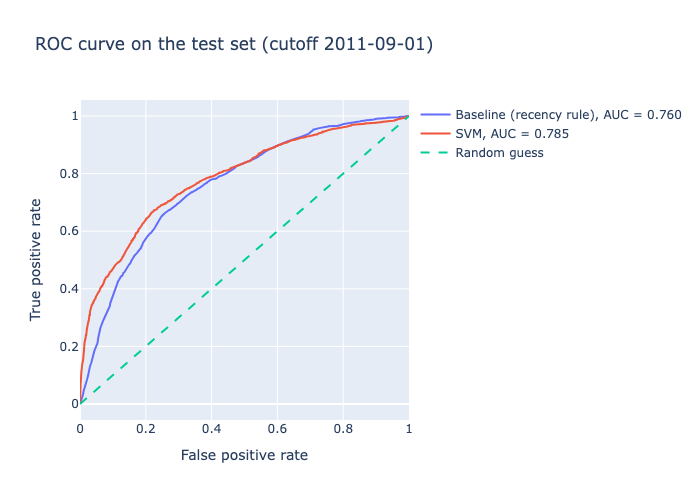

In [6]:
test = build_dataset(pd.read_parquet(CLEAN_PARQUET), TEST_CUTOFFS)
svm = joblib.load(SVM_MODEL)
svm_scores = svm.predict_proba(test[MODEL_FEATURES])[:, 1]
base_scores, _ = baseline_predict(test)

fig = go.Figure()
for name, s in [("Baseline (recency rule)", base_scores), ("SVM", svm_scores)]:
    fpr, tpr, _ = roc_curve(test["label"], s)
    print(f"{name}: test ROC-AUC = {roc_auc_score(test['label'], s):.3f}")
    fig.add_trace(go.Scatter(x=fpr, y=tpr, mode="lines",
                             name=f"{name}, AUC = {roc_auc_score(test['label'], s):.3f}"))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line_dash="dash", name="Random guess"))
fig.update_layout(title="ROC curve on the test set (cutoff " + TEST_CUTOFFS[0] + ")",
                  xaxis_title="False positive rate", yaxis_title="True positive rate")
fig.write_image(FIGURES_DIR / "roc_curve.png", width=800, height=600)
fig.show()

## 5. Confusion matrix (SVM at the chosen threshold)

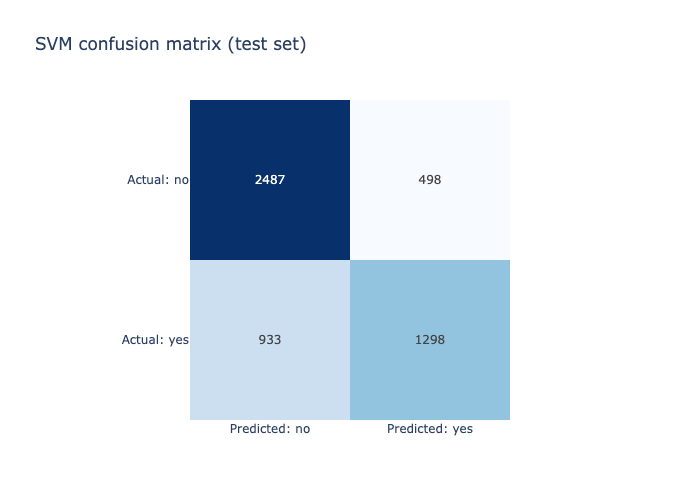

In [7]:
cm = report["test"]["svm"]["confusion_matrix"]
grid = [[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]]
fig = px.imshow(grid, text_auto=True, color_continuous_scale="Blues",
                x=["Predicted: no", "Predicted: yes"], y=["Actual: no", "Actual: yes"],
                title="SVM confusion matrix (test set)")
fig.update_layout(coloraxis_showscale=False)
fig.write_image(FIGURES_DIR / "confusion_matrix.png", width=600, height=500)
fig.show()

## 6. Which mistake costs more?
- **False positive:** we predict a customer will return, but they don't. Cost: a wasted discount or
  email, and a missed chance to run a proper win-back campaign.
- **False negative:** we predict they won't return, but they do. Cost: usually small (they bought anyway),
  unless it triggers an unnecessary win-back discount.

For a retention budget, false positives are usually the costlier error, so the SVM's higher precision
matters. Compare the two models directly:

In [8]:
b, s = report["test"]["baseline"]["confusion_matrix"], report["test"]["svm"]["confusion_matrix"]
pd.DataFrame({"baseline": b, "svm": s}).T.assign(
    precision=lambda d: d["tp"] / (d["tp"] + d["fp"]),
    recall=lambda d: d["tp"] / (d["tp"] + d["fn"])).round(3)

,tn,fp,fn,tp,precision,recall
baseline,2364,621,924,1307,0.678,0.586
svm,2487,498,933,1298,0.723,0.582


## 7. From scores to actions
The pipeline scores every customer as of the day after the last sale and maps the probability to an action tier.

In [9]:
scored = pd.read_parquet(PREDICTIONS_PARQUET)
scored["action"].value_counts().rename("customers").to_frame()

,customers
action,
Unlikely to return: win-back,3530
Undecided: nudge,1451
Likely to return: upsell,858


**Caveat:** these are **probabilities, not certainties**. A customer scored at 0.8 still has roughly a
1-in-5 chance of not returning. Use the scores to rank and prioritise customers, re-score regularly
as new orders arrive, and measure campaigns against a holdout group.